# BTC 옵션 PINN 연구: 실제 데이터로 한 단계씩 이해하기 (v5.0)

**연구의 시작부터 끝까지 같은 질문을 유지합니다.**

> **PINN은 시장 옵션가격을 잘 근사했는가? → 모델가격과 시장가격 차이가 이후 줄었는가? → 기초자산 방향성을 제거해도 유리했는가? → 실제 Bid/Ask에서 실행 가능한 순수익인가?**

이 노트북은 기존 v4.1의 복잡한 실험을 **검증 가능한 결과 중심으로 재구성한 독립 실행형 분석판**입니다. 2026년 11월 Deribit **실제 체결·가격·호가**를 담은 `deribit_pinn_rebuilt_2026.zip`에서 데이터를 직접 읽고, **보관된 실제 신경망 가중치를 이용해 가격을 다시 계산**합니다. 모델 재학습이나 과거 데이터 재다운로드를 기본 실행에 강제하지 않습니다.

**자료 구분**

- **관측값:** 체결가, BTC 지수가격, 당시에 수집한 Bid/Ask, 시간표시.
- **모형 추정값:** BS·NN·PINN 가격·Greeks, HAR-RV 예측, 모델 잔차.
- **연구 프록시:** 미래 *체결가* 변화, 한 구간 동안 Delta를 고정한 지수 헤지 손익. 실제 주문 체결/순수익이 아닙니다.
- **미검증:** 실제 옵션 진입·청산 및 BTC-PERPETUAL 체결, 펀딩, 계좌 순손익. 해당 기록이 없으면 누적 순수익 그래프를 생성하지 않습니다.

**Google Drive 연결 없음 · API Key 불필요 · 합성 거래자료 사용 없음.**

## 학습 순서: 네 개의 서로 다른 질문

| 단계 | 무엇을 측정하나? | 판단 가능한 내용 | 절대 혼동하지 말 것 |
|---|---|---|---|
| **1. 가격 근사** | 미래 날짜의 **그때 관측된** 옵션가격에 대한 RMSE | 모델이 옵션가격곡면을 얼마나 근사하는가 | 미래 가격 방향 예측 아님 |
| **2. 가격괴리** | `시장가격 - 모델가격`, 이후 잔차 변화 | 가격괴리가 줄어드는 경향이 있는가 | 잔차 감소 ≠ 매매 수익 |
| **3. 방향성 제거** | 관측 옵션가격 변화 + 초기 Delta × BTC 지수 변화 | BTC 방향성이 유리하게 움직인 효과를 얼마나 제거했나 | 지수는 거래 불가, 진짜 델타헤지 아님 |
| **4. 실행 가능성** | 실제 Bid/Ask와 포지션·체결 장부 | 비용 이후 수익 검증에 필요한 자료가 있는가 | 호가 한 시점으로 누적 손익 계산 불가 |

뒤의 그래프는 모두 **실제 관측값**에서 계산합니다. 각 단계마다 표본과 기간을 반드시 표시합니다.

## 0. 실행 준비: 결과 ZIP 하나를 업로드하세요

사용할 파일: `deribit_pinn_rebuilt_2026.zip` (기존 실험 결과 ZIP). Colab 왼쪽 파일창에 업로드하거나 아래 코드에서 선택할 수 있습니다. **ZIP에 들어 있는 CSV와 `.pt` 가중치만 사용**합니다. 이전 `WebSocket 352행` 기록은 이 ZIP에 들어 있지 않으므로 포함된 것처럼 표시하지 않습니다.

In [3]:
with zipfile.ZipFile(ZIP_FILE) as z:
    needed=['raw_real_deribit_trades.csv.gz','research_manifest.json','actual_trade_bars_4h.csv','oos_real_trade_predictions.csv',
            'oos_bs_index_iv_proxy_diagnostics.csv','mispricing_nonoverlapping_oos_events.csv',
            'observed_index_hedge_summary.csv','real_btc_har_rv_test.csv',
            'observed_expiry_iv_vs_har_24h_spread.csv','latest_live_option_quotes.csv',
            'data_only_nn_weights.pt','bs_pinn_weights.pt','data_only_train_curve.csv','pinn_train_curve.csv']
    missing=[f for f in needed if f not in z.namelist()]
    if missing: raise FileNotFoundError('ZIP 필수 자료 누락: '+str(missing))
    manifest=json.loads(z.read('research_manifest.json'))
    import gzip
    with z.open('raw_real_deribit_trades.csv.gz') as compressed:
        with gzip.GzipFile(fileobj=compressed) as raw_input:
            raw_trade_count = len(pd.read_csv(raw_input,usecols=['trade_id']))
    bars=read_csv(z,'actual_trade_bars_4h.csv')
    oos=read_csv(z,'oos_real_trade_predictions.csv')
    iv_diag=read_csv(z,'oos_bs_index_iv_proxy_diagnostics.csv')
    events=read_csv(z,'mispricing_nonoverlapping_oos_events.csv')
    hedge_original=read_csv(z,'observed_index_hedge_summary.csv')
    rv=read_csv(z,'real_btc_har_rv_test.csv')
    iv_rv=read_csv(z,'observed_expiry_iv_vs_har_24h_spread.csv')
    quotes=read_csv(z,'latest_live_option_quotes.csv')
    curve_data=read_csv(z,'data_only_train_curve.csv')
    curve_pinn=read_csv(z,'pinn_train_curve.csv')
    data_weights=z.read('data_only_nn_weights.pt')
    pinn_weights=z.read('bs_pinn_weights.pt')
for df in (bars,oos,iv_diag,events,rv,iv_rv,quotes):
    for col in ('ts','future_ts','signal_day','snapshot_ts','decision_ts','option_trade_ts'):
        if col in df.columns: df[col]=utc(df[col])
assert raw_trade_count==22911 and len(oos)==585 and len(bars)==2859, '이 노트북은 업로드한 특정 ZIP의 관측치 검증을 포함합니다. 데이터셋 버전을 확인하세요.'
assert (events.future_ts > events.ts).all(), '미래 시각 매칭에 오류가 있습니다.'
assert set(MODEL_ORDER).issubset(oos.columns)
print('확인한 실측 자료:',raw_trade_count,'raw trades,',len(bars),'4h bars,',len(oos),'OOS rows,',len(quotes),'quote snapshots')
print('테스트 기간 UTC:',oos.ts.min(),'~',oos.ts.max())
print('실시간 호가 기간 UTC:',quotes.snapshot_ts.min(),'~',quotes.snapshot_ts.max())

확인한 실측 자료: 22911 raw trades, 2859 4h bars, 585 OOS rows, 60 quote snapshots
테스트 기간 UTC: 2026-11-15 00:23:05.597000+00:00 ~ 2026-11-18 23:59:47.980000+00:00
실시간 호가 기간 UTC: 2026-11-20 13:04:20.066000+00:00 ~ 2026-11-20 13:04:32.420000+00:00


## 1. 데이터와 표본을 먼저 이해하기

**22,911건의 원시 체결**이 있었지만 가격 비교에 사용한 것은 계약·4시간 집계 후의 **2,859개 관측**입니다. 그중 과거 학습 1,601개, 검증 673개, 미래 날짜 테스트 585개입니다. 여기서 테스트 표본 585개는 서로 독립된 585일이 아니라 **4개 날짜의 반복 체결 관측치**입니다.

,Stage,Observed records,Interpretation
0,Raw trades,22911,Historical Deribit executed trades (reported i...
1,4-hour bars,2859,One last executed trade per instrument/bar
2,Train,1601,Price-model fitting
3,Validation,673,Early stopping
4,Test,585,Completely later 4 calendar days
5,Top-of-book quotes,60,"One UTC snapshot, NOT quote time series"


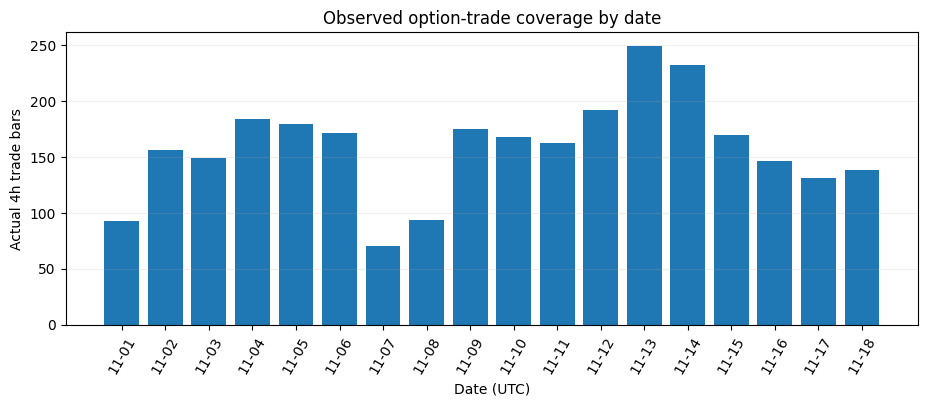

In [4]:
coverage=bars.assign(day=bars.ts.dt.floor('D')).groupby('day',as_index=False).size()
train_n=manifest['chronological_split']['train'];val_n=manifest['chronological_split']['validation'];test_n=manifest['chronological_split']['test']
summary=pd.DataFrame([
    ['Raw trades',raw_trade_count,'Historical Deribit executed trades (reported in prior run)'],
    ['4-hour bars',len(bars),'One last executed trade per instrument/bar'],
    ['Train',train_n,'Price-model fitting'],
    ['Validation',val_n,'Early stopping'],
    ['Test',test_n,'Completely later 4 calendar days'],
    ['Top-of-book quotes',len(quotes),'One UTC snapshot, NOT quote time series'],
],columns=['Stage','Observed records','Interpretation'])
display(summary)
plt.figure(figsize=(11,3.8))
plt.bar(coverage.day.dt.strftime('%m-%d'),coverage['size'])
plt.xticks(rotation=60)
plt.xlabel('Date (UTC)');plt.ylabel('Actual 4h trade bars');plt.title('Observed option-trade coverage by date')
plt.grid(axis='y',alpha=.2)
save_plot('01_observation_coverage')

## 2. 무엇을 학습했나? BS 가격을 보정하는 두 신경망

입력은 **로그머니니스** $x=\log(S/K)$, **잔존만기** $\tau$ 그리고 **콜/풋 구분**입니다.

$$V_{\mathrm{NN}}(S,K,\tau)=V_{\mathrm{BS}}(S,K,\tau;\sigma_0)+0.25K\tau f_\theta(x,\tau,\mathrm{CP})$$

- **Data-only NN:** 실제 옵션가격에 대한 오차(MSE)만 최소화
- **BS-PINN:** 같은 3–48–48–48–1 MLP에 **추가로 BS-PDE 잔차 MSE** 사용 (`weight=0.025`)
- **BS:** 학습일에 보정한 하나의 변동성 $\sigma_0\approx38\%$

다음 셀은 저장된 **진짜 `.pt` 가중치**를 읽어 모델의 가격 예측이 기존 CSV와 같은지 확인합니다. 다시 학습한 가짜 모델을 만들지 않습니다.

In [5]:
import torch
from torch import nn

sig0=float(manifest['bs_anchor_sigma_train_only'])

class BSAnchoredPriceNet(nn.Module):
    def __init__(self,sigma,width=48,r=0.):
        super().__init__()
        self.sigma,self.r=float(sigma),float(r)
        self.residual=nn.Sequential(nn.Linear(3,width),nn.Tanh(),nn.Linear(width,width),nn.Tanh(),
                                    nn.Linear(width,width),nn.Tanh(),nn.Linear(width,1))
    def forward(self,z):
        x=z[:,0:1]*.4; T=z[:,1:2]*.25; put=(z[:,2:3]>0)
        tau=T.clamp_min(1e-9);sqrt_t=torch.sqrt(tau)
        d1=(x+(self.r+.5*self.sigma**2)*tau)/(self.sigma*sqrt_t)
        d2=d1-self.sigma*sqrt_t
        Phi=lambda a:.5*(1+torch.erf(a/math.sqrt(2.)))
        er=torch.exp(-self.r*tau);m=torch.exp(x)
        call=m*Phi(d1)-er*Phi(d2)
        pv=er*Phi(-d2)-m*Phi(-d1)
        intrinsic=torch.where(put,torch.clamp(1-m,min=0),torch.clamp(m-1,min=0))
        anchor=torch.where(T<=0,intrinsic,torch.where(put,pv,call))
        return anchor+.25*T*self.residual(z)

def load_saved_net(raw,sigma):
    net=BSAnchoredPriceNet(sigma)
    net.load_state_dict(torch.load(BytesIO(raw),map_location='cpu',weights_only=True))
    return net.eval()

def recompute_price(net,frame):
    z=np.stack([frame.x.to_numpy(float)/.4,frame.tau.to_numpy(float)/.25,
                np.where(frame.cp.to_numpy()=='P',1.,-1.)],axis=1)
    with torch.no_grad():
        v=net(torch.as_tensor(z,dtype=torch.float32)).numpy().ravel()*frame.K.to_numpy(float)
    return v

network_data=load_saved_net(data_weights,sig0)
network_pinn=load_saved_net(pinn_weights,sig0)
validation=[]
for label,model in [('DataNN',network_data),('PINN',network_pinn)]:
    delta=np.abs(recompute_price(model,oos)-oos[label].to_numpy(float))
    validation.append({'model':label,'max_abs_reproduction_difference_USD':delta.max(),
                       'mean_abs_reproduction_difference_USD':delta.mean()})
check=pd.DataFrame(validation);display(check)
assert check.max_abs_reproduction_difference_USD.max()<1.0, '가중치와 CSV가 일치하지 않습니다. 확인이 필요합니다.'
print('검증 성공: 저장된 실제 가중치가 원본 CSV 가격을 거의 동일하게 재현합니다.')

,model,max_abs_reproduction_difference_USD,mean_abs_reproduction_difference_USD
0,DataNN,0.007961,0.001268
1,PINN,0.007679,0.001261


검증 성공: 저장된 실제 가중치가 원본 CSV 가격을 거의 동일하게 재현합니다.


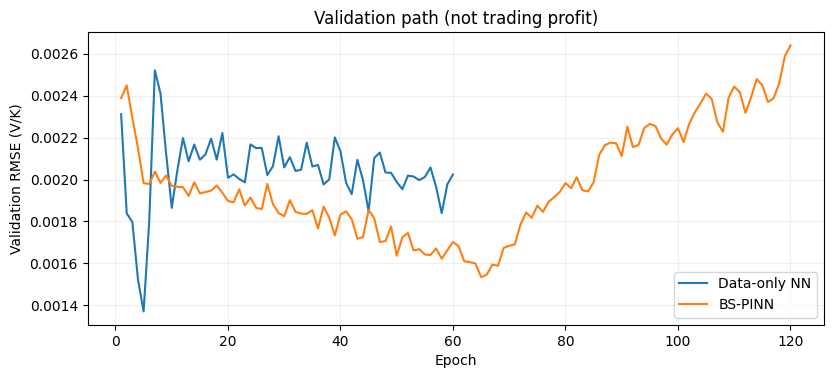

In [6]:
fig,ax=plt.subplots(figsize=(9.5,3.8))
ax.plot(curve_data['epoch'],curve_data['valid_norm_rmse'],label='Data-only NN')
ax.plot(curve_pinn['epoch'],curve_pinn['valid_norm_rmse'],label='BS-PINN')
ax.set(xlabel='Epoch',ylabel='Validation RMSE (V/K)',title='Validation path (not trading profit)')
ax.grid(alpha=.2);ax.legend()
save_plot('02_model_validation')

## 3. 시장가격을 얼마나 잘 근사했나? (미래 가격 예측이 아님)

**날짜는 학습 이후이지만, 모델 입력에는 그 날짜 당시의 BTC 지수가격 $S_t$가 들어갑니다.** 따라서 모델이 예측한 것은 **그 시점 시장에 존재하는 옵션가격**입니다. 미래 BTC 가격이나 미래 옵션가격을 직접 예측한 것이 아닙니다.

,model,MAE_USD,RMSE_USD,median_abs_USD
0,BS,108.88,140.34,83.00
1,DataNN,108.99,136.58,71.48
2,PINN,100.96,127.65,76.37


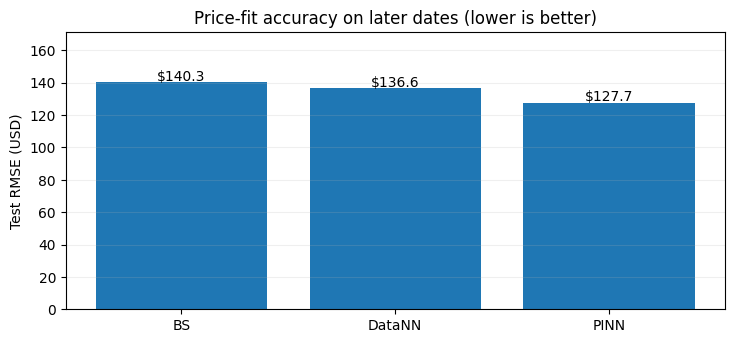

In [7]:
rows=[]
for name in MODEL_ORDER:
    er=oos[name].to_numpy(float)-oos.option_usd.to_numpy(float)
    rows.append({'model':name,'MAE_USD':np.mean(np.abs(er)),'RMSE_USD':np.sqrt(np.mean(er**2)),
                 'median_abs_USD':np.median(np.abs(er))})
metrics=pd.DataFrame(rows);display(metrics.round(2))
fig,ax=plt.subplots(figsize=(8.5,3.6))
ax.bar(metrics.model,metrics.RMSE_USD)
for i,v in enumerate(metrics.RMSE_USD):ax.text(i,v+1,f'${v:.1f}',ha='center')
ax.set(ylabel='Test RMSE (USD)',title='Price-fit accuracy on later dates (lower is better)')
ax.set_ylim(0,metrics.RMSE_USD.max()*1.22);ax.grid(axis='y',alpha=.2)
save_plot('03_test_price_rmse')

model,BS,DataNN,PINN
date,,,
11-15,138.4,122.9,110.5
11-16,146.6,123.7,114.6
11-17,141.7,141.5,136.4
11-18,134.5,159.0,149.9


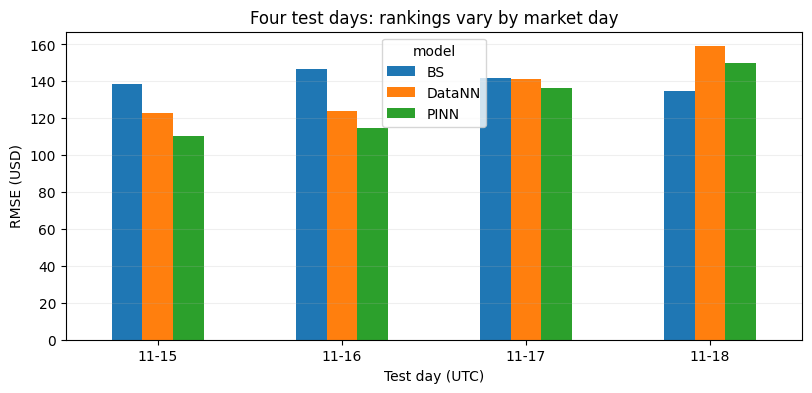

In [8]:
by_day=[]
for day,g in oos.groupby(oos.ts.dt.strftime('%m-%d')):
    for name in MODEL_ORDER:
        by_day.append({'date':day,'model':name,'n':len(g),'rmse':np.sqrt(np.mean((g[name]-g.option_usd)**2))})
daily=pd.DataFrame(by_day);display(daily.pivot(index='date',columns='model',values='rmse').round(1))
piv=daily.pivot(index='date',columns='model',values='rmse')[MODEL_ORDER]
piv.plot(kind='bar',figsize=(9.5,4),rot=0)
plt.ylabel('RMSE (USD)');plt.xlabel('Test day (UTC)')
plt.title('Four test days: rankings vary by market day')
plt.grid(axis='y',alpha=.2)
save_plot('04_test_rmse_by_day')

model,BS,DataNN,PINN
bucket,,,
$0-250,52.2,101.9,62.1
$1k-5k,192.1,114.1,156.3
$250-1k,110.1,128.9,108.0
$5k+,165.9,100.3,135.1


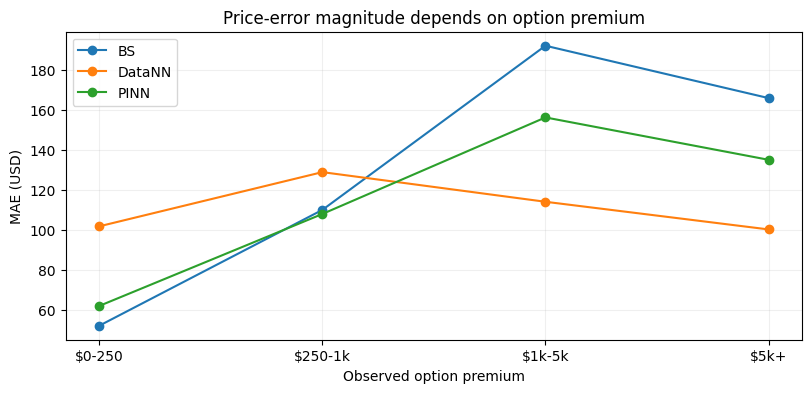

In [9]:
# 대형 내가격 옵션이 USD 오차 평가를 지배하는지 확인
p=oos.copy()
p['premium_bucket']=pd.cut(p.option_usd,[0,250,1000,5000,np.inf],labels=['$0-250','$250-1k','$1k-5k','$5k+'],include_lowest=True)
errs=[]
for bucket,g in p.groupby('premium_bucket',observed=True):
    for model in MODEL_ORDER:
        errs.append({'bucket':str(bucket),'model':model,'n':len(g),'mae':(g[model]-g.option_usd).abs().mean(),
                     'median_abs_relative_pct':np.median((g[model]-g.option_usd).abs()/g.option_usd)*100})
prem_err=pd.DataFrame(errs)
display(prem_err.pivot(index='bucket',columns='model',values='mae').round(1))
fig,ax=plt.subplots(figsize=(9.5,4))
for model in MODEL_ORDER:
    v=prem_err[prem_err.model==model].set_index('bucket').reindex(['$0-250','$250-1k','$1k-5k','$5k+'])
    ax.plot(v.index,v.mae,marker='o',label=model)
ax.set(ylabel='MAE (USD)',xlabel='Observed option premium',title='Price-error magnitude depends on option premium')
ax.legend();ax.grid(alpha=.2)
save_plot('05_price_error_by_option_premium')

## 3-1. IV(내재변동성) 정확도는 같은 표본에서만 비교

가격을 IV로 역산하는 과정은 일부 계약에서 실패합니다. 그래서 세 모델과 시장가격 모두 유효한 IV가 계산되는 **공통 표본**만 사용합니다. 이 IV는 Deribit의 공식 만기별 Forward 기반 값이 아니라, **동일한 현물 BS 가정으로 역산한 연구용 프록시**입니다.

,model,valid_iv_rows,common_rows,common_MAE_pp
0,BS,517,365,3.741
1,DataNN,367,365,4.246
2,PINN,415,365,3.890


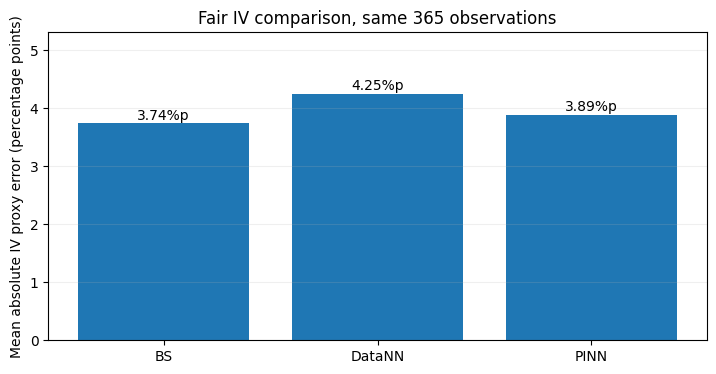

In [10]:
colmap={'BS':'abs_iv_error_pp_BS','DataNN':'abs_iv_error_pp_DataNN','PINN':'abs_iv_error_pp_PINN'}
common=iv_diag.dropna(subset=list(colmap.values())+['bs_index_iv_market']).copy()
counts=pd.DataFrame([{'model':model,'valid_iv_rows':int(iv_diag[col].notna().sum()),
                      'common_rows':len(common),'common_MAE_pp':common[col].mean()} for model,col in colmap.items()])
display(counts.round(3))
fig,ax=plt.subplots(figsize=(8.5,4))
ax.bar(counts.model,counts.common_MAE_pp)
for i,v in enumerate(counts.common_MAE_pp):ax.text(i,v+.06,f'{v:.2f}%p',ha='center')
ax.set(ylabel='Mean absolute IV proxy error (percentage points)',title=f'Fair IV comparison, same {len(common)} observations')
ax.grid(axis='y',alpha=.2);ax.set_ylim(0,counts.common_MAE_pp.max()*1.25)
save_plot('06_common_sample_iv_proxy_error')

## 4. 실제 거래 두 건을 연결해 보자: **성공처럼 보이는 경우 vs 착시**

각 행은 **과거에 실제 체결된 옵션가격**입니다. 아래 두 종목은 모두 PINN이 시장보다 낮게 평가하여 **매도 후보**였고, 이후 실제 옵션 체결가격이 하락했습니다. 그러나 BTC 지수 변화와 Delta를 고려하면 결론이 달라집니다.

**주의:** `4h`는 정확히 4시간 뒤 시장호가가 아니라 **4시간 이후 처음 매칭된 같은 계약의 실제 체결**입니다. 두 사례 모두 관측 간격이 더 깁니다.

In [11]:
# 이미 기록된 실제 사건만 선택. 수익이 좋아 보이도록 새 데이터를 생성하지 않습니다.
CASE_SPEC=[('A: residual contraction','BTC-25DEC26-74000-C','2026-11-15 02:06:50.027+00:00'),
           ('B: favorable price move, widening residual','BTC-25DEC26-68000-C','2026-11-15 03:02:39.038+00:00')]
case_rows=[]
for label,symbol,when in CASE_SPEC:
    e=events[(events.model=='PINN')&(events.horizon_h==4)&(events.instrument_name==symbol)&(events.ts==pd.Timestamp(when))]
    assert len(e)==1,(symbol,when)
    e=e.iloc[0]
    t=oos[(oos.instrument_name==symbol)&(oos.ts==e.ts)].iloc[0]
    u=oos[(oos.instrument_name==symbol)&(oos.ts==e.future_ts)].iloc[0]
    side=1 if e.residual_t>0 else -1 # 1: short option, -1: long option
    option_proxy=side*(t.option_usd-u.option_usd)
    index_hedge_proxy=side*t.PINN_delta*(u.S-t.S)
    case_rows.append({'case':label,'symbol':symbol,'entry_ts':t.ts,'exit_obs_ts':u.ts,
       'observed_hours':(u.ts-t.ts).total_seconds()/3600,'S_t':t.S,'S_h':u.S,
       'V_t':t.option_usd,'V_h':u.option_usd,'PINN_t':t.PINN,'PINN_h':u.PINN,
       'residual_t':e.residual_t,'residual_h':e.residual_h,
       'PINN_delta_t':t.PINN_delta,'option_move_proxy':option_proxy,
       'fixed_delta_index_hedge_proxy':index_hedge_proxy,
       'combined_index_proxy':option_proxy+index_hedge_proxy})
cases=pd.DataFrame(case_rows)
display(cases[['case','observed_hours','S_t','S_h','V_t','V_h','residual_t','residual_h','PINN_delta_t','option_move_proxy','fixed_delta_index_hedge_proxy','combined_index_proxy']].round(2))

,case,observed_hours,S_t,S_h,V_t,V_h,residual_t,residual_h,PINN_delta_t,option_move_proxy,fixed_delta_index_hedge_proxy,combined_index_proxy
0,A: residual contraction,5.73,63274.61,63855.71,727.66,574.70,281.51,58.21,0.12,152.96,71.38,224.34
1,"B: favorable price move, widening residual",5.32,65485.60,64225.74,2521.20,2055.22,214.41,249.07,0.42,465.97,-530.88,-64.91


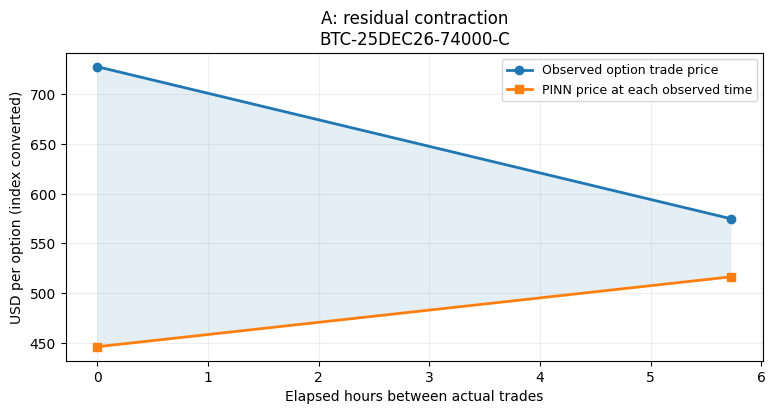

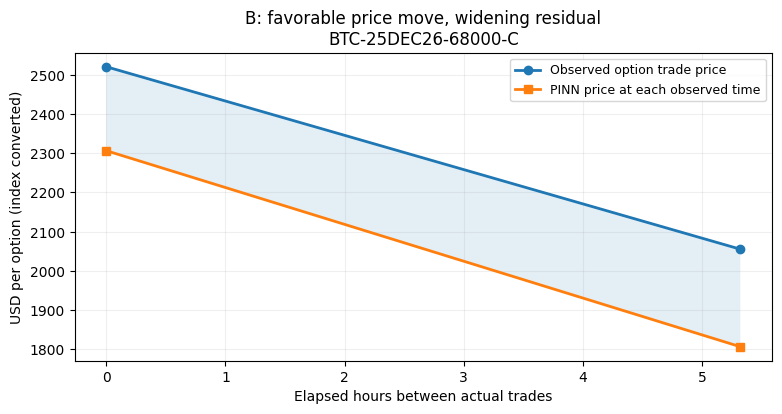

In [12]:
# 사례별 두 개의 '가격 시각화': 시장 체결가격, 모형 적정가격과 BTC 지수 변화를 구분
for idx,row in cases.iterrows():
    fig,ax=plt.subplots(figsize=(9,4))
    x=[0,row.observed_hours]
    ax.plot(x,[row.V_t,row.V_h],marker='o',lw=2,label='Observed option trade price')
    ax.plot(x,[row.PINN_t,row.PINN_h],marker='s',lw=2,label='PINN price at each observed time')
    ax.fill_between(x,[row.PINN_t,row.PINN_h],[row.V_t,row.V_h],alpha=.12)
    ax.set(xlabel='Elapsed hours between actual trades',ylabel='USD per option (index converted)',title=f'{row["case"]}\n{row.symbol}')
    ax.legend(fontsize=9);ax.grid(alpha=.2)
    save_plot(f'07{idx+1}_actual_case_prices')

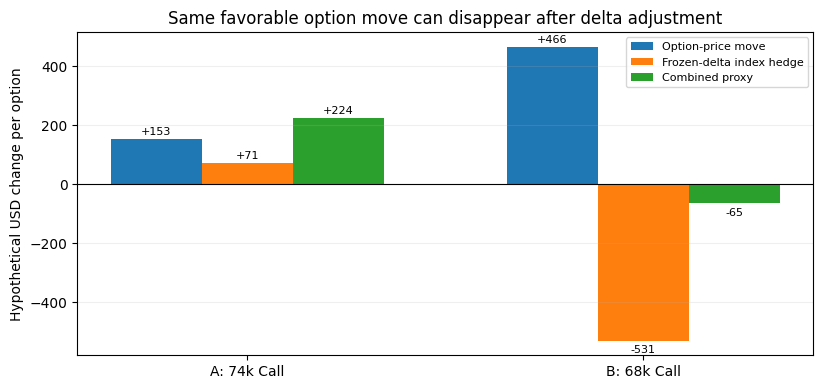

In [13]:
# 더 중요한 것은 방향성 제거 이후의 한 단계 손익: NO fees, NO executable hedge
fig,ax=plt.subplots(figsize=(9.5,4.2))
labels=['A: 74k Call','B: 68k Call']
x=np.arange(2); width=.23
for offset,col,name in [(-width,'option_move_proxy','Option-price move'),(0,'fixed_delta_index_hedge_proxy','Frozen-delta index hedge'),(width,'combined_index_proxy','Combined proxy')]:
    vals=cases[col].to_numpy(float)
    ax.bar(x+offset,vals,width,label=name)
    for xi,yi in zip(x+offset,vals):ax.text(xi, yi+(8 if yi>=0 else -14),f'{yi:+.0f}',ha='center',va=('bottom' if yi>=0 else 'top'),fontsize=8)
ax.axhline(0,color='black',lw=.8);ax.set_xticks(x,labels)
ax.set(ylabel='Hypothetical USD change per option',title='Same favorable option move can disappear after delta adjustment')
ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
save_plot('08_case_option_move_versus_delta_adjusted')

### 손익 분해식: **실제 순수익 아님**

모델 잔차 $e_t=V_t^{market}-V_t^{model}$가 양수면 옵션을 *매도*하는 방향을 가정하고, 음수면 *매수*하는 방향을 가정합니다.

$$\Pi_{\rm option\ proxy} = \operatorname{sgn}(e_t)\,(V_t-V_h)$$
$$\Pi_{\rm index\ hedge\ proxy} = \operatorname{sgn}(e_t)\,\Delta_t^{\rm PINN}\,(S_h-S_t)$$

이때 $\Delta_t$를 관측기간 전체에 **고정**했으며, BTC 지수를 실제로 거래했다고 가정하지 않습니다. 더구나 Deribit 옵션과 선물은 코인 결제/inverse 구조이므로 이는 옵션·선물의 정확한 현금흐름 계산이 아닙니다. **Bid/Ask, 헤지 조정, 수수료, 펀딩, 체결 지연**도 없습니다.

**실증적 해석:** B 사례는 옵션 체결가격이 매도 방향으로 내려갔지만, BTC 가격 하락이 헤지에 불리하게 작용해 지수 헤지 프록시는 음수가 됩니다. 그래서 가격 방향 적중과 Alpha를 분리해야 합니다.

## 5. 특정 성공 사례를 전체 데이터로 확장하면?

이제 개별 사례 두 건이 아니라, 같은 계약이 일정 시간 지난 후 **실제로 다시 거래된 사건**을 사용합니다. 기존 연구는 모델별로 4시간 목표 사건 256건을 남겼습니다. 하지만 4개 날짜에서 나온 관측이므로 독립 표본이 수백 개라고 해석해서는 안 됩니다.

또한 `horizon_h=4`는 **4시간 이상 지난 다음에 발견된 체결**을 뜻하므로, 실제 보유시간 분포를 표시합니다.

4h-target signal events: 768 rows across 3 models, 4 distinct signal dates; each model has 256 cases.


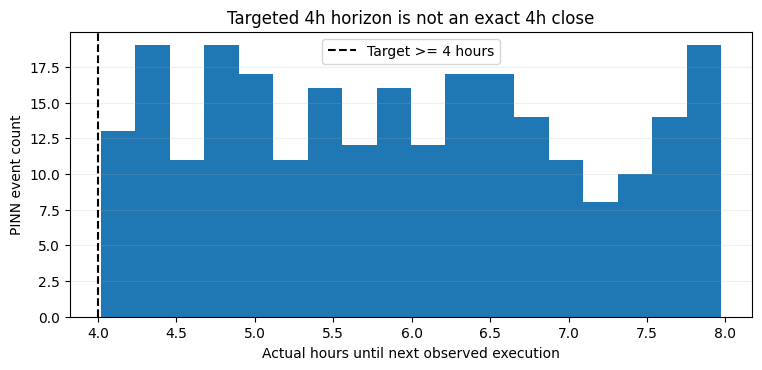

In [14]:
e4=events[events.horizon_h==4].copy()
e4['actual_hours']=(e4.future_ts-e4.ts).dt.total_seconds()/3600
obs_days=e4.ts.dt.floor('D').nunique()
print(f'4h-target signal events: {len(e4)} rows across 3 models, {obs_days} distinct signal dates; each model has {len(e4[e4.model=="PINN"])} cases.')
fig,ax=plt.subplots(figsize=(8.8,3.7))
ax.hist(e4[e4.model=='PINN']['actual_hours'],bins=18)
ax.axvline(4,color='black',linestyle='--',label='Target >= 4 hours')
ax.set(xlabel='Actual hours until next observed execution',ylabel='PINN event count',title='Targeted 4h horizon is not an exact 4h close')
ax.legend();ax.grid(axis='y',alpha=.2)
save_plot('09_actual_signal_holding_duration')

In [15]:
# 외부 가정을 새로 만들어내지 않고, OOS CSV의 동일 시각 초기 Delta와 미래 실제 체결 시각의 S만 사용.
current=oos.set_index(['instrument_name','ts'],verify_integrity=True)
left=e4.merge(oos[['instrument_name','ts','S','option_usd','K','tau','cp','DataNN_delta','PINN_delta']],on=['instrument_name','ts'],validate='many_to_one')
future=(oos[['instrument_name','ts','S','option_usd']].rename(columns={'ts':'future_ts','S':'S_future','option_usd':'V_future'}))
work=left.merge(future,on=['instrument_name','future_ts'],validate='many_to_one')
assert len(work)==len(e4)
work['side_short_is_positive']=np.where(work.residual_t>=0,1.,-1.)
d1=(np.log(work.S/work.K)+.5*sig0**2*work.tau)/(sig0*np.sqrt(work.tau))
work['BS_delta']=ndtr(d1)-np.where(work.cp=='P',1.,0.)
work['entry_delta']=np.select([work.model=='BS',work.model=='DataNN',work.model=='PINN'],
                              [work.BS_delta,work.DataNN_delta,work.PINN_delta],default=np.nan)
work['gross_option_move']=work.side_short_is_positive*(work.option_usd-work.V_future)
work['initial_delta_hedge']=work.side_short_is_positive*work.entry_delta*(work.S_future-work.S)
work['index_delta_adjusted_proxy']=work.gross_option_move+work.initial_delta_hedge
assert np.allclose(work.gross_option_move,work.unhedged_trade_change_proxy,atol=1e-4), '원본 수익 프록시와 재계산 결과 불일치'
assert work.entry_delta.notna().all()
work['signal_bucket_calc']=pd.cut(work.residual_t.abs(),[0,50,100,200,500,np.inf],
                                 labels=['0–50','50–100','100–200','200–500','500+'],include_lowest=True)
print('독립 신호 날짜:',work.ts.dt.floor('D').nunique(),', 옵션 계약 수:',work.instrument_name.nunique())
print('Gross signal-proxy values matched against original CSV successfully.')

독립 신호 날짜: 4 , 옵션 계약 수: 35
Gross signal-proxy values matched against original CSV successfully.


,model,signal_bucket_calc,n,unique_days,mean_gross,mean_adjusted,share_adjusted_positive
0,BS,0–50,82,4,-17.42,-9.12,0.33
1,BS,50–100,68,4,51.31,-2.20,0.47
2,BS,100–200,79,4,65.38,10.07,0.51
3,BS,200–500,27,4,81.71,31.85,0.56
4,DataNN,0–50,67,4,-46.05,-10.92,0.31
5,DataNN,50–100,87,4,54.06,5.13,0.52
6,DataNN,100–200,63,4,-65.42,1.95,0.37
7,DataNN,200–500,38,4,33.42,8.41,0.42
8,PINN,0–50,75,4,3.39,-2.16,0.36
9,PINN,50–100,84,4,29.10,4.43,0.49


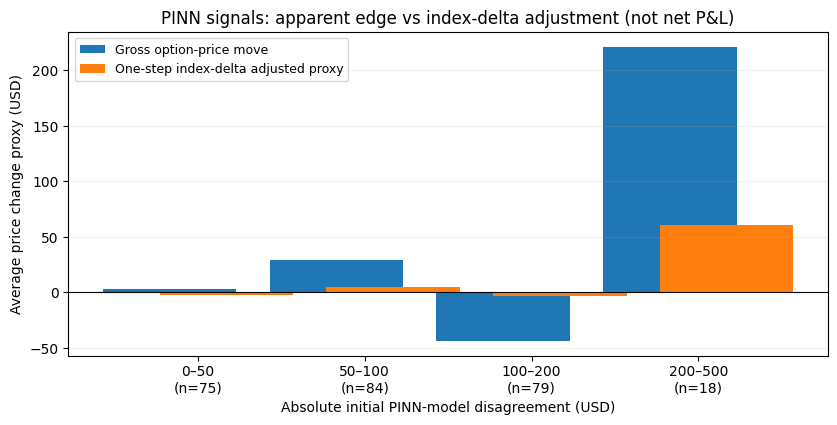

In [16]:
# 중요한 구간의 변화: 매매 방향 유리함 vs 기초가격 방향성 제거 후
f=work[work.signal_bucket_calc.isin(['0–50','50–100','100–200','200–500'])].copy()
agg=(f.groupby(['model','signal_bucket_calc'],observed=True)
      .agg(n=('gross_option_move','size'),unique_days=('ts',lambda x:x.dt.floor('D').nunique()),
           mean_gross=('gross_option_move','mean'),mean_adjusted=('index_delta_adjusted_proxy','mean'),
           share_adjusted_positive=('index_delta_adjusted_proxy',lambda x:(x>0).mean()))
      .reset_index())
display(agg.round(2))
selection=agg[agg.model=='PINN'].set_index('signal_bucket_calc').reindex(['0–50','50–100','100–200','200–500'])
fig,ax=plt.subplots(figsize=(9.8,4.2))
x=np.arange(len(selection));w=.34
ax.bar(x-w/2,selection.mean_gross,label='Gross option-price move')
ax.bar(x+w/2,selection.mean_adjusted,label='One-step index-delta adjusted proxy')
ax.axhline(0,color='black',lw=.8)
ax.set_xticks(x,[f'{k}\n(n={int(n)})' for k,n in zip(selection.index,selection.n)])
ax.set(xlabel='Absolute initial PINN-model disagreement (USD)',ylabel='Average price change proxy (USD)',
       title='PINN signals: apparent edge vs index-delta adjustment (not net P&L)')
ax.legend(fontsize=9);ax.grid(axis='y',alpha=.2)
save_plot('10_pinn_signal_gross_and_index_hedged_proxy')

,n,days,avg_gross,avg_delta_adjusted,positive_fraction
model,,,,,
BS,27,4,81.71,31.85,0.56
DataNN,38,4,33.42,8.41,0.42
PINN,18,4,221.23,60.67,0.61


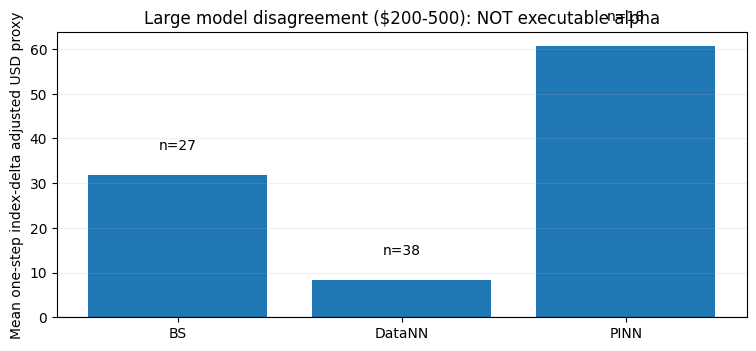

In [17]:
# 모델 간 비교도 동일 4h 목표 사건만; 각 모형의 신호 방향은 서로 다를 수 있음
comp=work[work.residual_t.abs().between(200,500, inclusive='left')].groupby('model').agg(
    n=('index_delta_adjusted_proxy','size'),days=('ts',lambda x:x.dt.floor('D').nunique()),
    avg_gross=('gross_option_move','mean'),avg_delta_adjusted=('index_delta_adjusted_proxy','mean'),
    positive_fraction=('index_delta_adjusted_proxy',lambda x:(x>0).mean())).reindex(MODEL_ORDER)
display(comp.round(2))
fig,ax=plt.subplots(figsize=(8.9,3.7))
ax.bar(comp.index,comp.avg_delta_adjusted)
ax.axhline(0,color='black',lw=.8)
for i,(v,n) in enumerate(zip(comp.avg_delta_adjusted,comp.n)):
    ax.text(i,v+(5 if v>=0 else -5),f'n={int(n)}',ha='center',va=('bottom' if v>=0 else 'top'))
ax.set(ylabel='Mean one-step index-delta adjusted USD proxy',title='Large model disagreement ($200-500): NOT executable alpha')
ax.grid(axis='y',alpha=.2)
save_plot('11_large_disagreement_model_comparison')

## 6. 기존 델타헤지 연구는 왜 위 가격괴리 전략과 별개인가?

다음 표는 원래 연구에서 **45개 옵션 계약을 모두 숏옵션으로 놓고**, BS·Data-only·PINN Delta로 지수 기반 헤지 회계를 비교한 결과입니다. 이는 **가격괴리 신호가 발생한 계약만 골라서 거래한 전략이 아닙니다.** 그 차이를 구분해야 합니다.

,contracts,avg_net_pnl,median_abs_net_pnl,mean_assumed_cost
model,,,,
BS,45,-99.61,84.19,34.17
DataNN,45,-117.36,119.24,34.28
PINN,45,-112.00,106.29,33.59


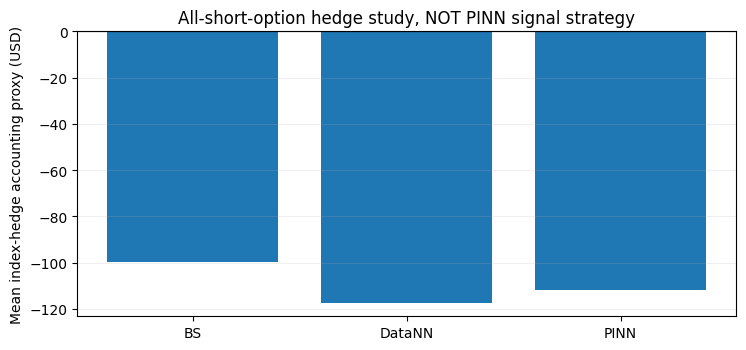

In [18]:
h5=hedge_original[hedge_original.bps_assumed==5].set_index('model').reindex(MODEL_ORDER)
display(h5[['contracts','avg_net_pnl','median_abs_net_pnl','mean_assumed_cost']].round(2))
fig,ax=plt.subplots(figsize=(8.5,3.7))
ax.bar(h5.index,h5.avg_net_pnl)
ax.axhline(0,color='black',lw=.8)
ax.set(ylabel='Mean index-hedge accounting proxy (USD)',title='All-short-option hedge study, NOT PINN signal strategy')
ax.grid(axis='y',alpha=.2)
save_plot('12_separate_all_short_delta_hedge_study')

## 7. HAR-RV: 이것은 **별도의 미래 변동성 예측** 연구

- 입력: 최근 BTC 지수가격에서 계산한 1·3·7일 변동성
- 목표: **미래 24시간 실현변동성**
- 기준모델: 최근 24시간 변동성을 그대로 미래에 사용하는 Naive

주의: 여러 4시간 시작 시점에서 미래 24시간을 예측하므로 **타깃 구간이 서로 겹칩니다.** 18개 행을 독립적인 18개 거래일로 계산하지 않습니다.

HAR-RV MAE (%p): 16.27  | Naive MAE (%p): 28.0  | n: 18


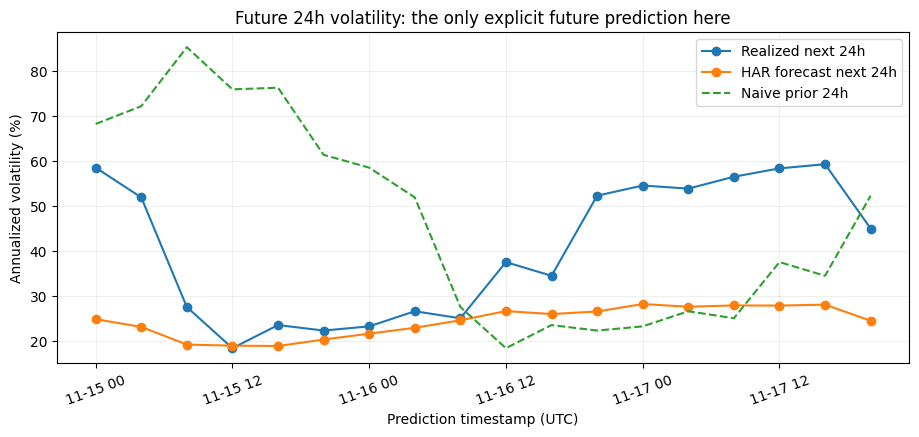

In [19]:
rv=rv.sort_values('ts').copy()
r_mae=float(np.mean(np.abs(rv.forecast_vol-rv.realized_vol_next24)))
n_mae=float(np.mean(np.abs(rv.naive_vol-rv.realized_vol_next24)))
print('HAR-RV MAE (%p):',round(r_mae*100,2),' | Naive MAE (%p):',round(n_mae*100,2),' | n:',len(rv))
fig,ax=plt.subplots(figsize=(11,4.3))
ax.plot(rv.ts,rv.realized_vol_next24*100,'-o',label='Realized next 24h')
ax.plot(rv.ts,rv.forecast_vol*100,'-o',label='HAR forecast next 24h')
ax.plot(rv.ts,rv.naive_vol*100,'--',label='Naive prior 24h')
ax.set(ylabel='Annualized volatility (%)',xlabel='Prediction timestamp (UTC)',title='Future 24h volatility: the only explicit future prediction here')
ax.grid(alpha=.2);ax.legend();plt.xticks(rotation=20)
save_plot('13_future_rv_har_comparison')

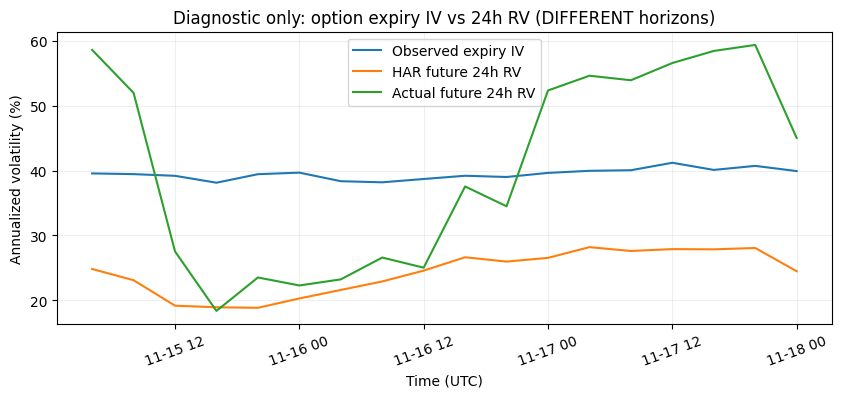

In [20]:
# 관측 IV는 옵션 만기까지의 IV; HAR는 24h RV → 반드시 기간 차이를 표시
iv_rv=iv_rv.sort_values('decision_ts').copy()
fig,ax=plt.subplots(figsize=(10,3.8))
ax.plot(iv_rv.decision_ts,100*iv_rv.market_option_iv,label='Observed expiry IV')
ax.plot(iv_rv.decision_ts,100*iv_rv.har_forecast_vol_next24,label='HAR future 24h RV')
ax.plot(iv_rv.decision_ts,100*iv_rv.actual_realized_vol_next24,label='Actual future 24h RV')
ax.set(xlabel='Time (UTC)',ylabel='Annualized volatility (%)',title='Diagnostic only: option expiry IV vs 24h RV (DIFFERENT horizons)')
ax.legend();ax.grid(alpha=.2);plt.xticks(rotation=20)
save_plot('14_iv_vs_24h_rv_different_horizons')

## 8. 실제 시장에서 거래 가능했을까? — Bid/Ask 한 시점만 확인됨

ZIP의 `latest_live_option_quotes.csv`는 2026-11-20의 **약 12초짜리 단일 시장 단면**입니다. 최우선 Bid·Ask는 거래비용의 단서지만, 이것만으로 다음 날 재매수·재매도나 델타헤지 체결가격을 알 수는 없습니다.

특히 앞서 분석한 11월 15~18일 체결 사례에 **11월 20일 스프레드를 소급 적용하면 안 됩니다.**

Quote rows: 60 UTC span seconds: 12.4
Spread median (% of mid): 3.23  | range: 1.03 to 16.67


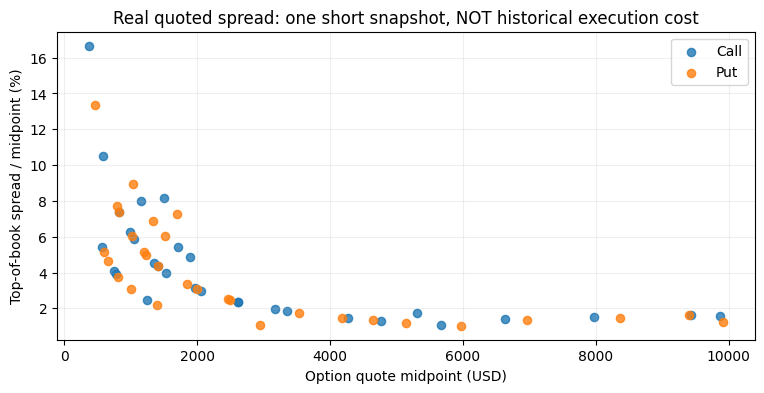

In [21]:
quotes['mid_usd']=(quotes.bid_usd+quotes.ask_usd)/2
quotes['spread_usd']=quotes.ask_usd-quotes.bid_usd
quotes['spread_pct_mid']=100*quotes.spread_usd/quotes.mid_usd.replace(0,np.nan)
quotes_good=quotes[(quotes.bid_usd>0)&(quotes.ask_usd>=quotes.bid_usd)&np.isfinite(quotes.spread_pct_mid)].copy()
print('Quote rows:',len(quotes_good), 'UTC span seconds:',round((quotes.snapshot_ts.max()-quotes.snapshot_ts.min()).total_seconds(),1))
print('Spread median (% of mid):',round(quotes_good.spread_pct_mid.median(),2),' | range:',
      round(quotes_good.spread_pct_mid.min(),2),'to',round(quotes_good.spread_pct_mid.max(),2))
fig,ax=plt.subplots(figsize=(9,4))
for cp,g in quotes_good.groupby('cp'):
    ax.scatter(g.mid_usd,g.spread_pct_mid,label='Call' if cp=='C' else 'Put',alpha=.8,s=35)
ax.set(xlabel='Option quote midpoint (USD)',ylabel='Top-of-book spread / midpoint (%)',
       title='Real quoted spread: one short snapshot, NOT historical execution cost')
ax.legend();ax.grid(alpha=.2)
save_plot('15_real_snapshot_bid_ask_spread')

## 9. 왜 누적 순수익 그래프가 없는가? (누락을 0원으로 오해하지 않기)

실제 수익을 만들려면 **진입시점 Ask/Bid, 청산시점 Bid/Ask, 선물 헤지 체결, 수수료, 펀딩, 포지션 크기**가 필요합니다. 현재 ZIP에는 이 장부가 없습니다.

아래 셀은 **실제 계좌에서 확인된 손익 장부 CSV가 있을 때만** 누적 순수익을 그립니다. 가상의 체결기록을 만들지 않습니다. 필요한 열은 `close_ts`, `strategy`, `realized_net_pnl_btc`입니다. 사용자 기록을 추가하기 전에는 결과가 ‘미검증’으로 나타나는 것이 정상입니다.

In [22]:
# 사용자가 실제 계좌의 체결·정산 결과를 보유한 경우에만 입력 (선택)
ACTUAL_FILL_LEDGER_CSV = ''  # 예: '/content/my_verified_realized_ledger.csv'; 기본은 공란
if not ACTUAL_FILL_LEDGER_CSV:
    print('미검증: 실제 계좌 체결·정산 장부가 없습니다. 누적 NET P&L 그래프 생성 안 함.')
    print('현재 ZIP의 단일 호가 스냅샷만으로 4h/24h 뒤 청산 가격을 알 수 없습니다.')
else:
    ledger=pd.read_csv(ACTUAL_FILL_LEDGER_CSV)
    need={'close_ts','strategy','realized_net_pnl_btc'}
    if not need.issubset(ledger.columns):raise ValueError(f'실현 장부 컬럼 누락: {need-set(ledger.columns)}')
    ledger['close_ts']=utc(ledger.close_ts)
    ledger['realized_net_pnl_btc']=pd.to_numeric(ledger.realized_net_pnl_btc,errors='raise')
    assert ledger.realized_net_pnl_btc.notna().all()
    fig,ax=plt.subplots(figsize=(10,4))
    for label,grp in ledger.groupby('strategy'):
        tr=grp.groupby('close_ts').realized_net_pnl_btc.sum().sort_index().cumsum()
        ax.step(tr.index,tr.values,where='post',label=str(label))
    ax.axhline(0,color='black',lw=.8)
    ax.set(ylabel='Cumulative ACTUAL net BTC',xlabel='Verified close time UTC',title='User-verified realized net ledger only')
    ax.legend();ax.grid(alpha=.2)
    save_plot('16_optional_actual_net_pnl')

미검증: 실제 계좌 체결·정산 장부가 없습니다. 누적 NET P&L 그래프 생성 안 함.
현재 ZIP의 단일 호가 스냅샷만으로 4h/24h 뒤 청산 가격을 알 수 없습니다.


## 10. 결론을 한 표로 정리 (데이터가 입증한 것과 미입증을 분리)

| 연구 질문 | 현재 CSV에서 확인된 답 | 수준 |
|---|---|---|
| PINN이 테스트가격을 잘 근사하는가? | 이번 4일의 RMSE에서는 가장 낮음 | **가격 근사 성과** |
| PINN이 IV도 항상 가장 정확한가? | 동일 유효 표본에서는 BS가 더 낮은 평균 IV 프록시 오차 | **일관된 우위 아님** |
| PINN이 미래 가격 변화를 정확히 예측했나? | 이를 직접 학습하지 않았음. 과거 적정가격 잔차가 미래에 수렴하는지 별도 탐색 | **Alpha 미검증** |
| 큰 가격괴리가 돈이 됐나? | 일부 유리한 옵션가격 변화는 BTC 방향성과 헤지 보정으로 설명 가능 | **실행 가능한 순수익 아님** |
| HAR가 미래 변동성을 예측했나? | Naive보다 이 18개 예측의 평균 오차 낮음 | **짧고 겹치는 구간의 예비 성과** |
| 실제 Bid/Ask로 수익을 냈나? | 역사적 호가 시계열과 실제 체결 장부 없음 | **미검증** |

**연구의 다음 단계:** 새로 축적한 동일 계약의 옵션·선물 Bid/Ask 시계열을 신호 시각과 실제 청산 시각에 연결하여, 지수 헤지 프록시가 아닌 *실제 계약 규격 기반 현금흐름*을 검증합니다.

In [23]:
# 마지막 자동 품질 검사 + 주요 결과 CSV 저장 + ZIP 준비
assert oos.ts.dt.floor('D').nunique()==4
assert events.future_ts.gt(events.ts).all()
assert quotes.snapshot_ts.dt.floor('D').nunique()==1
assert not np.isfinite(work['index_delta_adjusted_proxy']).eq(False).any()
for name,d in [('price_metrics_v5.csv',metrics),('daily_rmse_v5.csv',daily),('iv_common_comparison_v5.csv',counts),
               ('actual_case_studies_v5.csv',cases),('signal_index_hedge_proxy_v5.csv',work),
               ('signal_by_bucket_v5.csv',agg),('real_quote_spread_v5.csv',quotes_good)]:
    d.to_csv(OUT/name,index=False)
run_manifest={'source_zip':ZIP_FILE.name,'actual_raw_trade_rows_reported':raw_trade_count,'actual_4h_bars':len(bars),
              'actual_test_rows':len(oos),'independent_test_days':4,'real_quote_rows':len(quotes),
              'real_quote_days':1,'alpha_verified':False,'realized_net_pnl_verified':bool(ACTUAL_FILL_LEDGER_CSV),
              'plots':[p.name for p in PLOT_FILES]}
with open(OUT/'analysis_manifest.json','w',encoding='utf-8') as f:json.dump(run_manifest,f,ensure_ascii=False,indent=2)
print('검증 완료. PNG 차트:',len(PLOT_FILES),'개; 출력 폴더:',OUT)
print('예측가격·가격괴리·델타프록시·실시간호가·실현손익을 서로 다른 종류로 표시했습니다.')

검증 완료. PNG 차트: 16 개; 출력 폴더: /content/btc_pinn_v5_explained
예측가격·가격괴리·델타프록시·실시간호가·실현손익을 서로 다른 종류로 표시했습니다.


In [24]:
# 로컬 산출물만 ZIP으로 저장. 다운로드는 선택사항이며 Google Drive를 사용하지 않습니다.
import shutil
ARCHIVE=Path('/content/btc_pinn_v5_explained_results.zip' if Path('/content').exists() else '/mnt/data/btc_pinn_v5_explained_results.zip')
shutil.make_archive(str(ARCHIVE.with_suffix('')),'zip',root_dir=OUT)
print('Result archive:',ARCHIVE)
# Colab에서 자동 다운로드를 원한다면 다음 주석 해제:
# from google.colab import files; files.download(str(ARCHIVE))

Result archive: /content/btc_pinn_v5_explained_results.zip
